### 向量艺术：检索器的概念
---
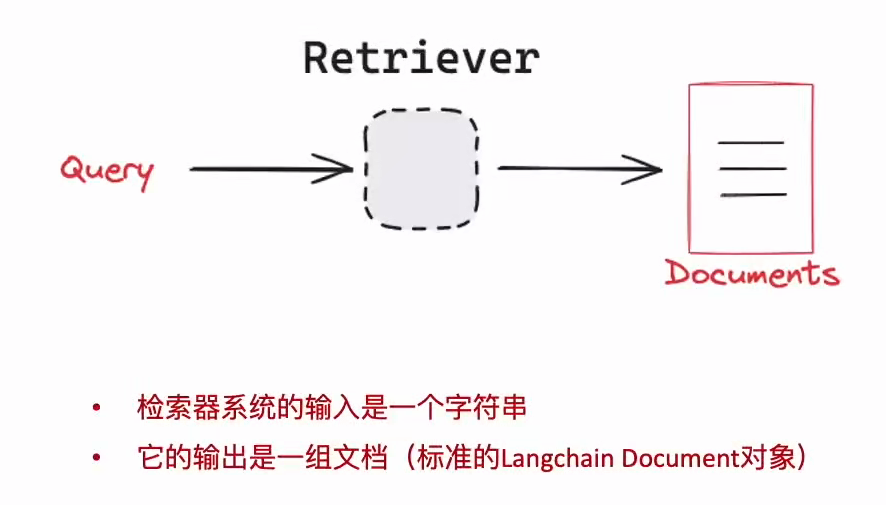

- 检索器系统是Langchian的概念封装
- 包含了除存储外的所有RAG系统
- 它将用户输入与知识库碎片关联
- 召回率是衡量检索器的重要指标
- 它是一个标准的Runnable组件
- 所有的向量存储都可以转为检索器
- 最简单的使用 as_retriver


### 向量艺术：检索器在Langchain中的实践
---
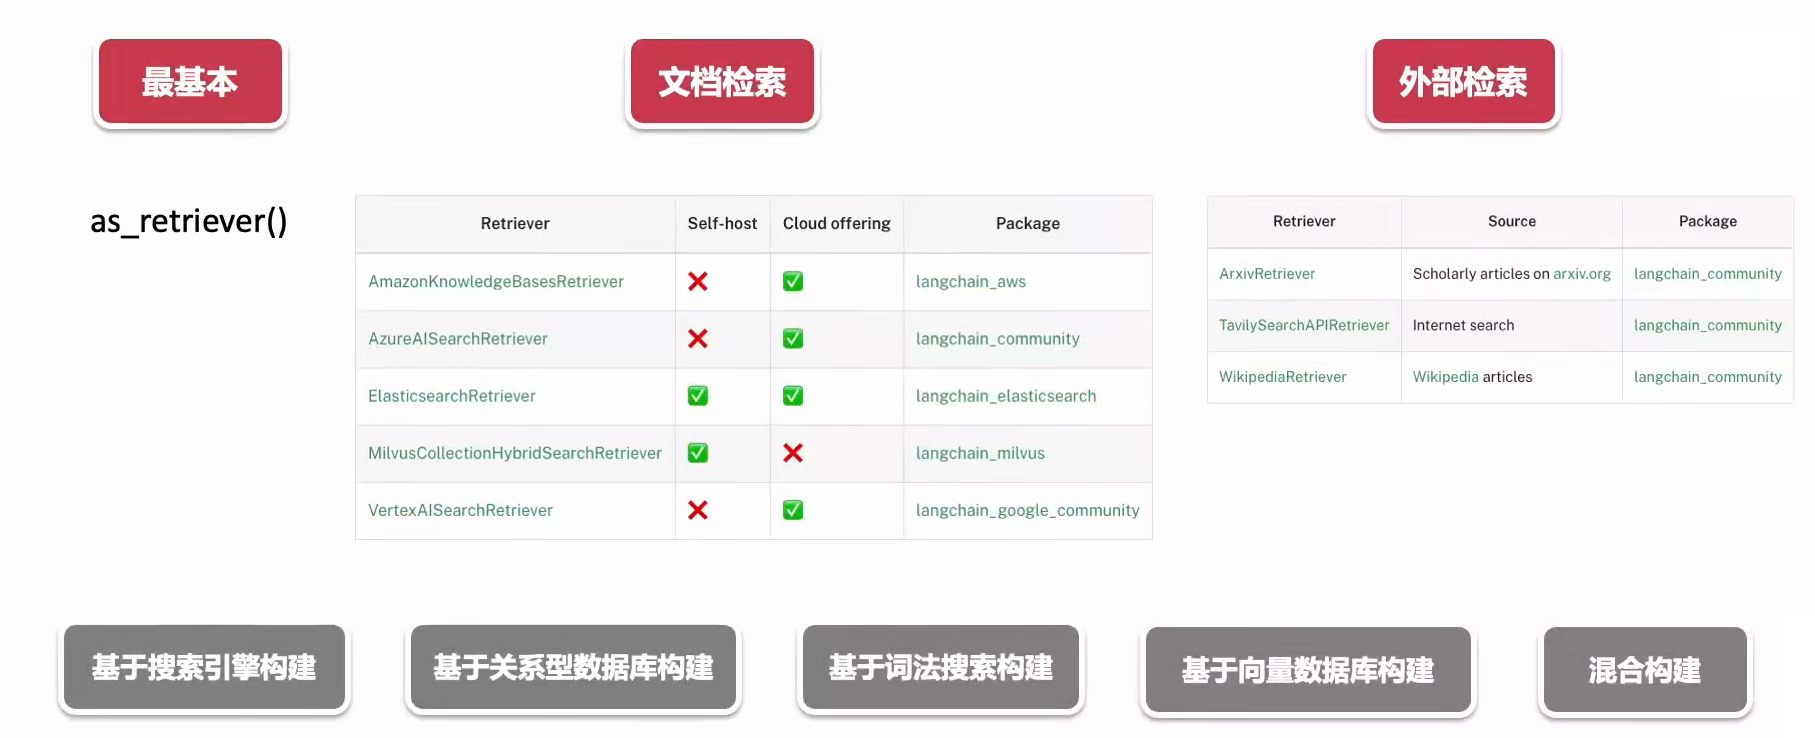

- 基本的检索器
- 词法搜索构建：BM25

### 基本检索器设置
---

In [9]:
from langchain_community.document_loaders import TextLoader
from langchain_community.vectorstores import FAISS
from langchain_openai import OpenAIEmbeddings
from langchain_text_splitters import CharacterTextSplitter
from dotenv import load_dotenv
import os

load_dotenv()

loader = TextLoader("test.txt", encoding="utf-8")

documents = loader.load()
text_spliter = CharacterTextSplitter(chunk_size=1000, chunk_overlap=0)
texts = text_spliter.split_documents(documents)
embeddings = OpenAIEmbeddings(
    model="Qwen/Qwen3-Embedding-8B",
    openai_api_key=os.getenv("api_key"),
    openai_api_base=os.getenv("base_url")
)

vectorstore = FAISS.from_documents(texts, embeddings)

实例化检索器

In [10]:
retriever = vectorstore.as_retriever()

docs = retriever.invoke("deepseek 是什么？")

docs

[Document(id='1adab2b0-ef2e-4e57-85b6-92ae2286f815', metadata={'source': 'test.txt'}, page_content='DeepSeek（深度求索）是一家中国的人工智能研究公司（杭州深度求索人工智能基础技术研究有限公司），在人工智能和大语言模型（LLM）领域非常知名。\n它主要以开发高性能、高性价比的开源和闭源大模型而受到全球 AI 社区和开发者的广泛关注。以下是 DeepSeek 的几个核心特点和代表性产品：\n代表性模型：\nDeepSeek-V3：其最新一代的通用大语言模型，在多项权威基准测试中表现出色，性能媲美国际顶尖的闭源模型，同时大幅降低了训练和推理成本。\nDeepSeek-R1：专注于强化学习和推理能力的模型，在数学、科学和逻辑推理等复杂任务上表现优异，且开源了其推理过程。\nDeepSeek-Coder：专门针对代码生成、理解和调试优化的模型，在开发者社区中非常受欢迎。\nDeepSeek-Math：专注于数学推理和解题的专用模型。\n开源贡献：DeepSeek 坚持开源策略，将其许多核心模型（包括模型权重和训练技术细节）向社区开放，极大地推动了全球开源 AI 生态的发展。\n技术创新：他们在模型架构（如混合注意力机制、多 Token 预测技术）和训练方法（如混合专家架构 MoE、强化学习）上有很多创新，使得模型在保持高性能的同时，显著降低了算力消耗。\n简而言之，DeepSeek 是目前全球 AI 领域最具影响力和竞争力的中国大模型研发团队之一，尤其在开源社区和代码/推理垂直领域享有很高的声誉。')]

### BM25也称为Okapi BM25，是信息检索系统中用来估计文档与给定搜索查询的相关性的排名函数。

---

In [11]:
! pip install --upgrade --quiet rank_bm25

In [13]:
from langchain_community.retrievers import BM25Retriever
vretriever = BM25Retriever.from_texts(["foo", "bar", "world", "hello", "foo bar"])

# 使用所创建的文档来创建一个新的检索器
from langchain_core.documents import Document

retriever = BM25Retriever.from_documents(
    [
        Document(page_content="foo"),
        Document(page_content="bar"),
        Document(page_content="world"),
        Document(page_content="hello"),
        Document(page_content="foo bar"),
    ]
)

result = retriever.invoke("foo")

result

[Document(metadata={}, page_content='foo'),
 Document(metadata={}, page_content='foo bar'),
 Document(metadata={}, page_content='hello'),
 Document(metadata={}, page_content='world')]

使用预处理器进行增强，在词语级别检索效果比较显著

punkt是一个句子分割器模型

In [ ]:
import os
# 通过环境变量允许
os.environ["NLTK_ALLOW_PROXIED_URLOPEN"] = "1"

import nltk
# 方法 B：通过 NLTK 内部设置允许（二选一即可，建议都加上）
import nltk.pathsec
nltk.pathsec.ALLOW_PROXIED_FETCH = True

# 然后重新下载你需要的数据包
nltk.download('punkt_tab')
nltk.download('punkt') # LangChain 分词通常也需要这个
nltk.download('averaged_perceptron_tagger')

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Lxb\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Lxb\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\Lxb\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!


True

In [28]:
from nltk.tokenize import word_tokenize

retriever = BM25Retriever.from_documents(
    [
        Document(page_content="foo"),
        Document(page_content="bar"),
        Document(page_content="world"),
        Document(page_content="hello"),
        Document(page_content="foo bar"),
    ],
    k=2,
    preprocess_func=word_tokenize,
)

result = retriever.invoke("bar")
result

[Document(metadata={}, page_content='bar'),
 Document(metadata={}, page_content='foo bar')]